In [4]:
import pandas as pd
import chromadb
from PIL import Image
from transformers import pipeline
from weavingtools.embedding_tools import SigLIPEmbedder, ImageLoaderRGB
from weavingtools.linkage_tools import plot_query_results

In [5]:
# load the collection as csv
collection_df = pd.read_csv('data/heritage_weaver_data.csv')
print('Collections has',collection_df.shape[0],'rows')

# initate the image loader
data_loader = ImageLoaderRGB()

# initiate the client
client = chromadb.PersistentClient(path="hw-08-10") # hw-16-08 | hw-08-10

# search strategies
datadict = {'original': ('heritage-weaver-base','google/siglip-base-patch16-224'),
            'historical': ('heritage-weaver-ft-best','Kaspar/siglip-heritage-weaver-best'),}

Collections has 31319 rows


In [6]:
len(collection_df.record_id.unique())

21871

In [7]:
# select the database
colection = 'original' # 'original' or 'historical'
collection_name, checkpoint_name = datadict[colection]
print('Using',collection_name,'and',checkpoint_name)

Using heritage-weaver-base and google/siglip-base-patch16-224


In [8]:
# initialise the embedder which we will attach to the database
siglip_embedder = SigLIPEmbedder(checkpoint_name)
# initiate the collection in the database
collection_db = client.get_or_create_collection(
                                            name=collection_name, 
                                            metadata={"hnsw:space": "cosine"}, # we will use cosine distance for similarity search
                                            embedding_function=siglip_embedder, # the embedder for the collection (text and images)
                                            data_loader=data_loader # procedure for loading the image data
                                            )

print(f'Number of items in database = {collection_db.count()}')

Number of items in database = 108220


# Text to Image Search

In [9]:
query_text = 'a portrait with a braded hair'

In [10]:
results = collection_db.query(
                query_texts=[ query_text ], where={'modality':'image'})
query_df = plot_query_results(results, source='img_path')

# Cross Collection Image to Image Search

Crystal wireless receiving set made in Great Britain, with the brand name Midge and Post Office approval number 902


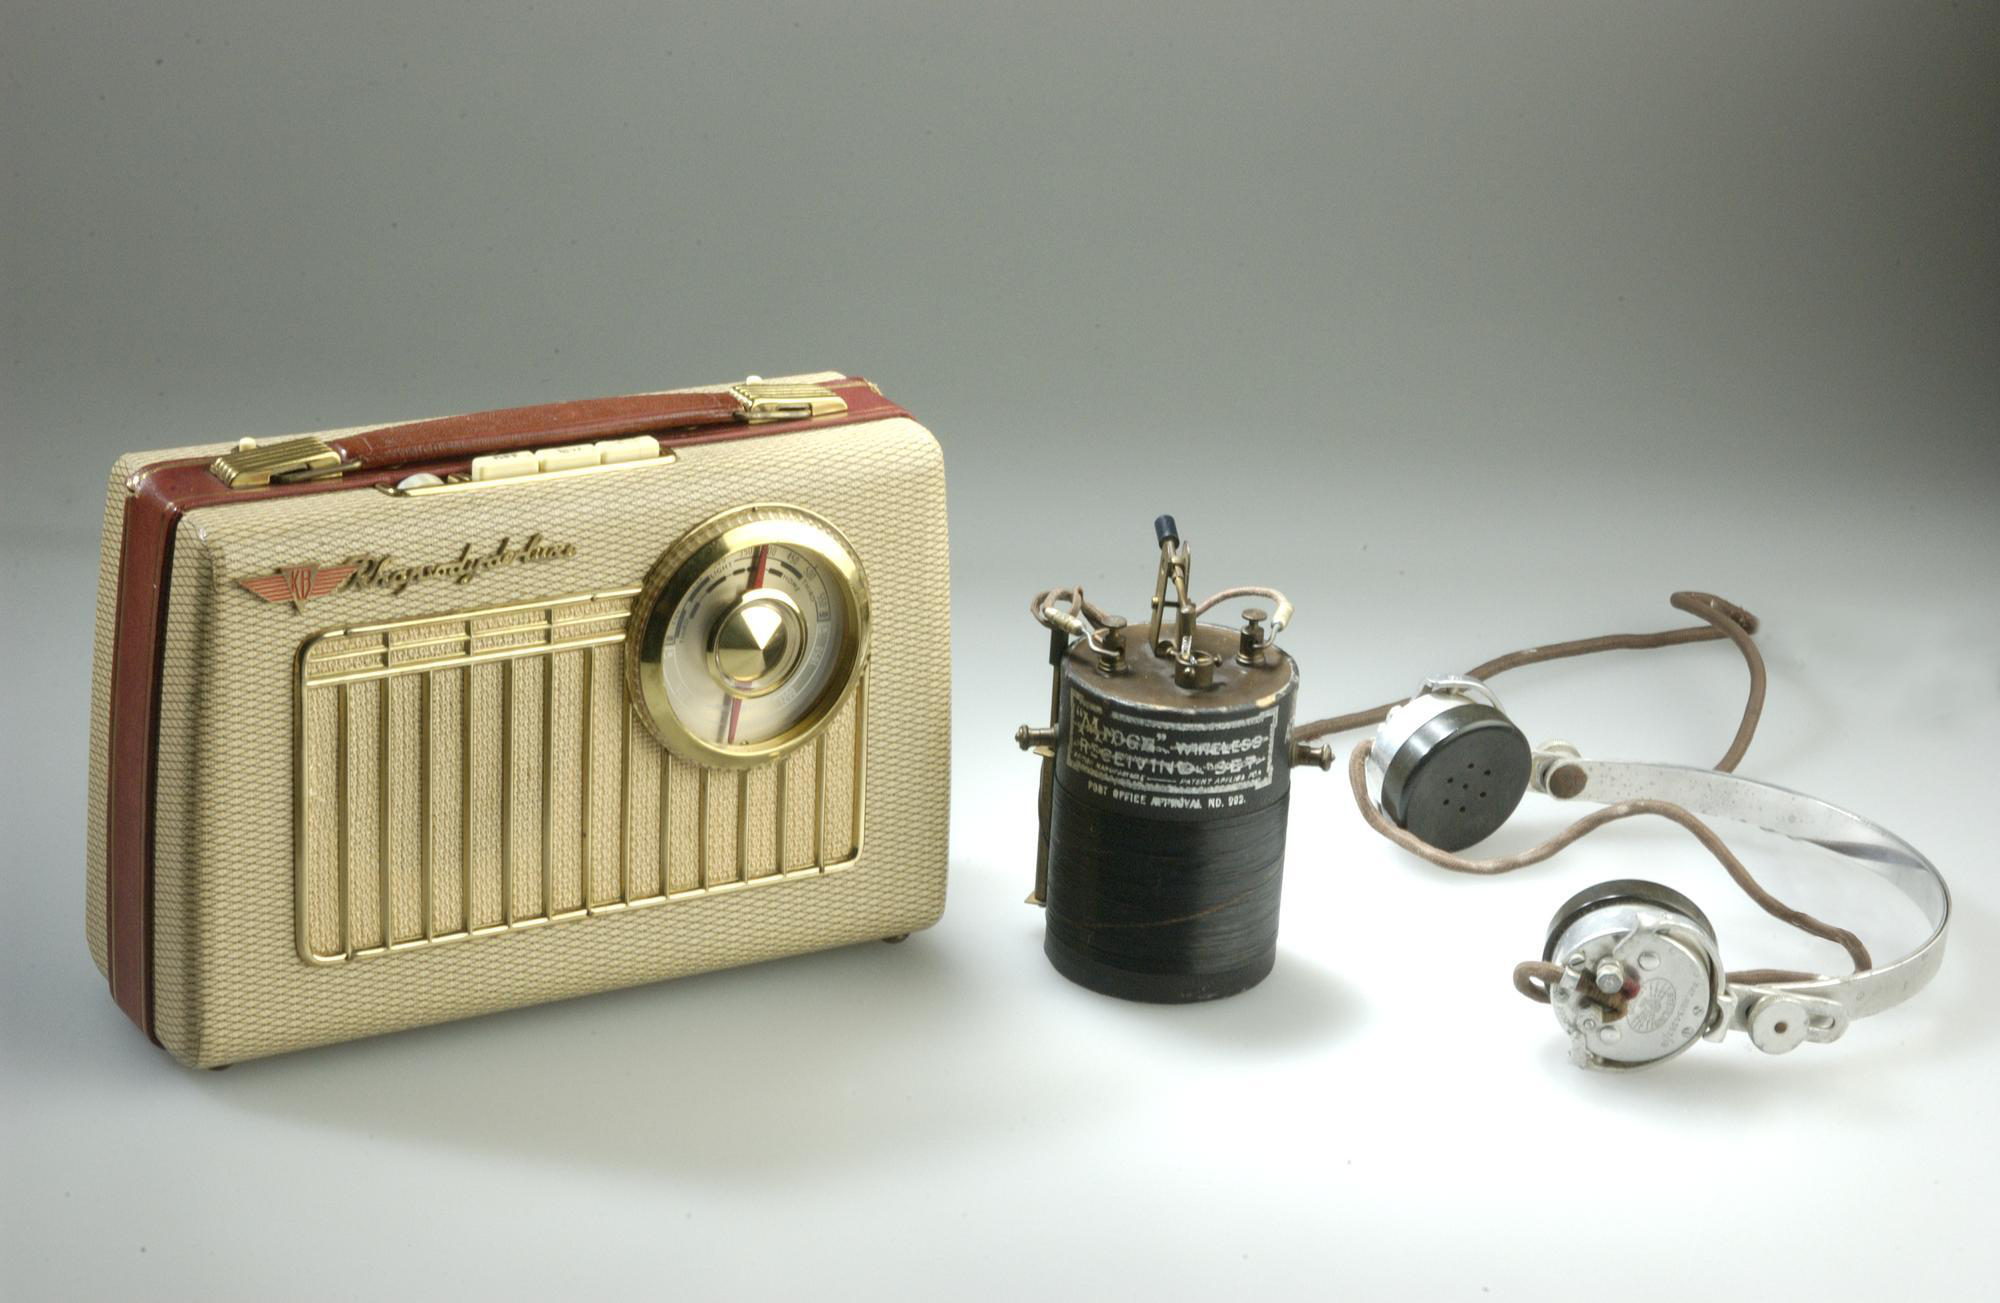

In [51]:
idx = 323 #323
row = collection_df[collection_df.collection=='nms'].iloc[idx]
print(row.description)
Image.open(row.img_path)

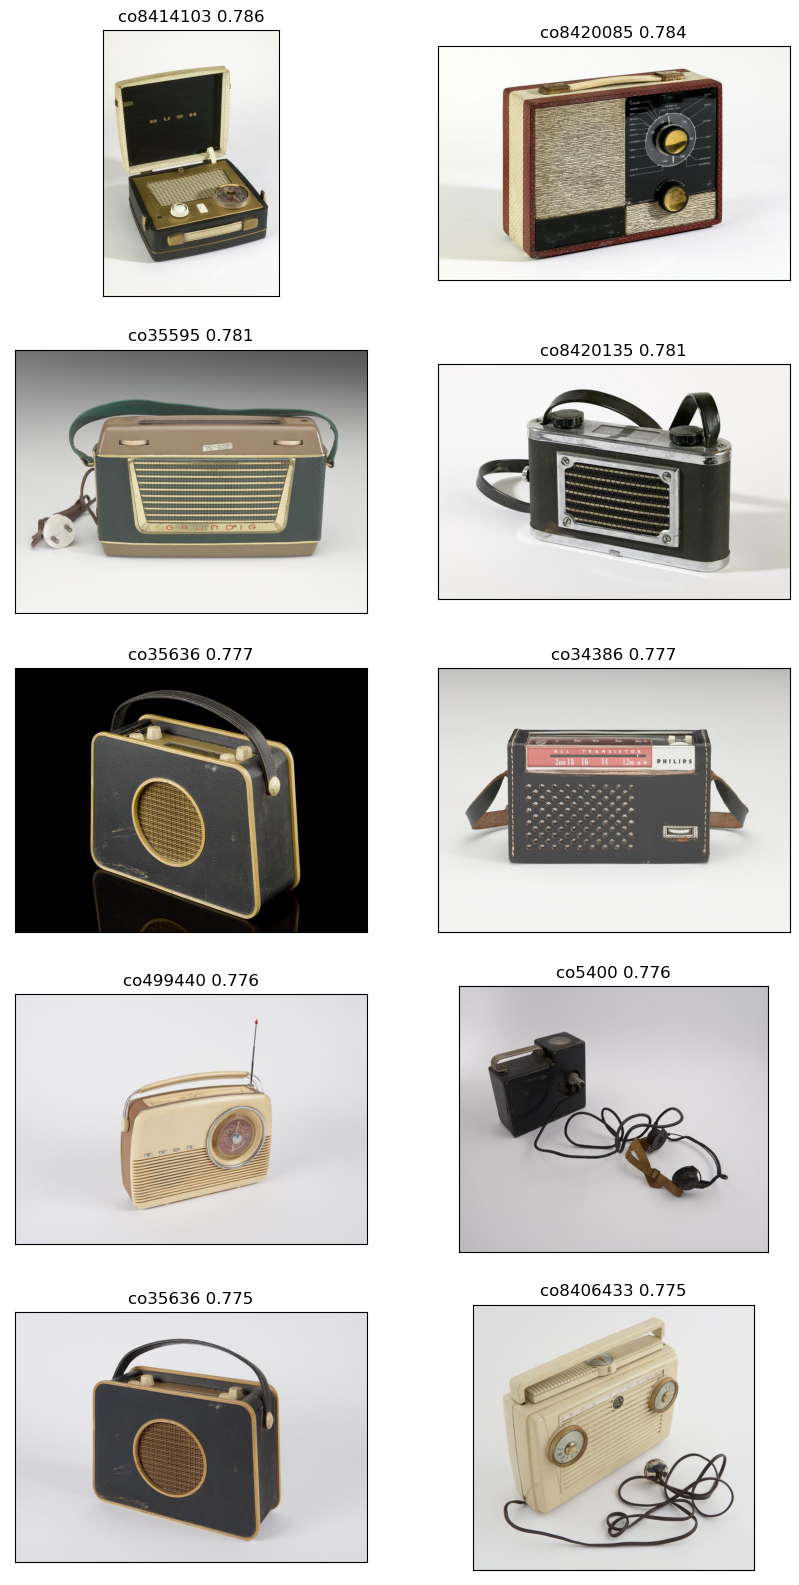

In [52]:
filters = {
    "$and": [
        {
            "modality": {
                "$eq": "image"
            }
        },
        {
            "collection": {
                "$eq" : "smg"
            }
        }
    ]
}

results = collection_db.query(query_uris=[row.img_path],where=filters, n_results=25)
query_df = plot_query_results(results, source='img_path')

# Zero-Shot Classification: What's in This Picture?

Wooden telephone receiver..

Wooden telephone receiver.


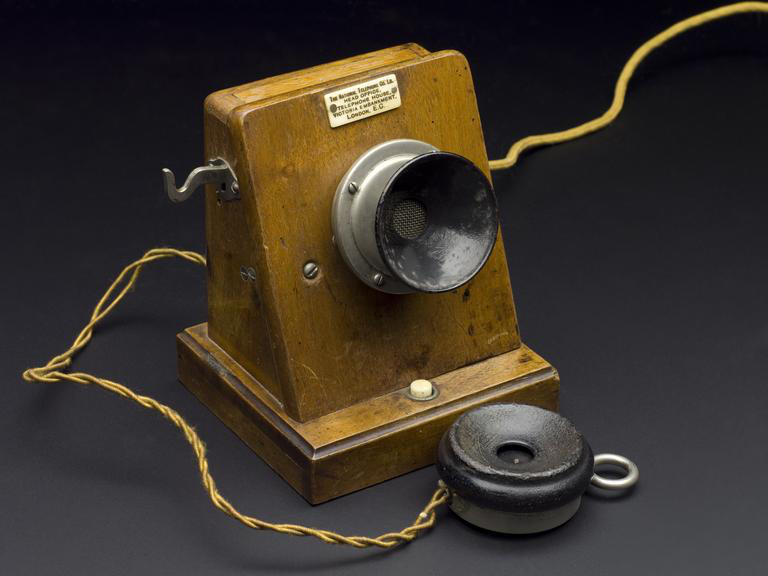

In [9]:
row = collection_df[collection_df.record_id=='co8054835'].iloc[0]
img = Image.open(row.img_path)
print(row.description)
img

In [42]:
checkpoint_name = 'Kaspar/siglip-heritage-weaver-best' # 'google/siglip-base-patch16-224' | 'Kaspar/siglip-heritage-weaver-best'
detector = pipeline(model=checkpoint_name, task="zero-shot-image-classification")


<AxesSubplot:title={'center':'Zero-shot classification'}, xlabel='label'>

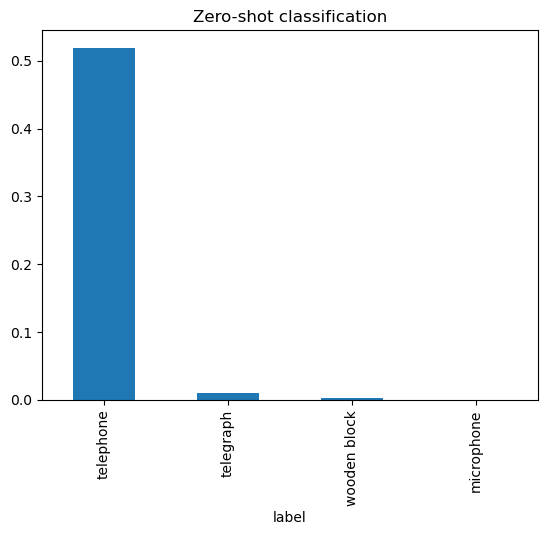

In [43]:
results = detector(img, candidate_labels=['wooden block', 'telephone','microphone','telegraph'])
pd.DataFrame(results).plot(kind='bar', x='label', y='score', legend=None, title='Zero-shot classification')